# Exercise 1 – Multi-Layer Perceptron Classifier

Train a three-layer MLP on CIFAR-10. Use the official training partition for a seeded training/validation split, then evaluate once on the untouched official test partition after training.

## 1. Model and method

Flatten each 32×32 RGB image to 3,072 values, then map them through 3,072 → 512 → 256 → 10 dense units. ReLU activations provide nonlinear transformations; CrossEntropyLoss and Adam are used for ten-class classification.

To compare this MLP with the CNN under the same training setup, this model uses no dropout. Flattening removes the image grid, so the MLP does not directly use local neighborhoods or share filters across image locations.

## 2. Shared setup and reproducibility

This notebook uses the same seed-42 setup, CIFAR-10 normalization, and 45,000/5,000 split as Exercises 2 and 4. The dataset is downloaded only if its local folder is missing.

In [1]:
import json
import sys
import random
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import torch.nn as nn
from IPython.display import Markdown, display
from sklearn.metrics import classification_report, confusion_matrix
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

SEED = 42

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(SEED)
PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
print("Python:", sys.executable)
DATA_DIR = PROJECT_ROOT / "data"
CIFAR_DIR = DATA_DIR / "cifar-10-batches-py"
ARTIFACT_DIR = PROJECT_ROOT / "artifacts" / "exercise_1"
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DOWNLOAD_DATA = not CIFAR_DIR.exists()
print("Project:", PROJECT_ROOT)
print("Device:", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))


Python: D:\AI ML\AI-ML-assessment-cifar10-project\.venv\Scripts\python.exe
Project: D:\AI ML\AI-ML-assessment-cifar10-project
Device: cuda
GPU: NVIDIA GeForce RTX 3050 Laptop GPU


## 3. Preprocessing, split, and loaders

Use the shared CIFAR-10 channel means and standard deviations. The seeded permutation is applied only to the official 50,000-image training partition. A separate, non-shuffled training loader is reserved for clean evaluation-mode metrics.

In [2]:
CIFAR_MEAN = (0.4914, 0.4822, 0.4465)
CIFAR_STD = (0.2470, 0.2435, 0.2616)
BATCH_SIZE = 64
EPOCHS = 20
LEARNING_RATE = 1e-3

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(CIFAR_MEAN, CIFAR_STD),
])
train_val_dataset = datasets.CIFAR10(
    root=str(DATA_DIR), train=True, download=DOWNLOAD_DATA, transform=transform
)
assert len(train_val_dataset) == 50_000
split_indices = torch.randperm(
    50_000, generator=torch.Generator().manual_seed(42)
).tolist()
train_dataset = Subset(train_val_dataset, split_indices[:45_000])
val_dataset = Subset(train_val_dataset, split_indices[45_000:])
loader_args = {
    "batch_size": BATCH_SIZE,
    "num_workers": 0,
    "pin_memory": DEVICE.type == "cuda",
}
train_loader = DataLoader(
    train_dataset, shuffle=True,
    generator=torch.Generator().manual_seed(SEED), **loader_args,
)
train_eval_loader = DataLoader(train_dataset, shuffle=False, **loader_args)
val_loader = DataLoader(val_dataset, shuffle=False, **loader_args)
CLASS_NAMES = train_val_dataset.classes
print(f"Training: {len(train_dataset):,}; validation: {len(val_dataset):,}")
print("Classes:", CLASS_NAMES)


Training: 45,000; validation: 5,000
Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


## 4. Three-layer MLP

The flattening and activation operations have no trainable parameters. The model has exactly three trainable Linear layers.

In [3]:
class SimpleMLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(3 * 32 * 32, 512)
        self.relu1 = nn.ReLU()
        self.fc2 = nn.Linear(512, 256)
        self.relu2 = nn.ReLU()
        self.fc3 = nn.Linear(256, 10)

    def forward(self, x):
        x = self.flatten(x)
        x = self.relu1(self.fc1(x))
        x = self.relu2(self.fc2(x))
        return self.fc3(x)

model = SimpleMLP().to(DEVICE)
trainable_layers = [m for m in model.modules() if isinstance(m, nn.Linear)]
assert len(trainable_layers) == 3
TRAINABLE_PARAMETERS = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(model)
print("Trainable layers:", len(trainable_layers))
print("Trainable parameters:", f"{TRAINABLE_PARAMETERS:,}")


SimpleMLP(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (fc1): Linear(in_features=3072, out_features=512, bias=True)
  (relu1): ReLU()
  (fc2): Linear(in_features=512, out_features=256, bias=True)
  (relu2): ReLU()
  (fc3): Linear(in_features=256, out_features=10, bias=True)
)
Trainable layers: 3
Trainable parameters: 1,707,274


## 5. Training and validation

Use CrossEntropyLoss and Adam. The per-epoch training metrics are accumulated while the model trains; validation metrics are measured in evaluation mode. After training, `evaluate()` measures the full training and validation subsets in evaluation mode.

In [4]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
history = {key: [] for key in ("train_loss", "train_accuracy", "val_loss", "val_accuracy")}

def train_epoch(model, loader, optimizer):
    model.train()
    loss_sum = 0.0
    correct = 0
    sample_count = 0
    for images, labels in loader:
        try:
            images = images.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            logits = model(images)
            loss = criterion(logits, labels)
            loss.backward()
            optimizer.step()
            n = labels.size(0)
            loss_sum += loss.item() * n
            correct += (logits.argmax(dim=1) == labels).sum().item()
            sample_count += n
        except torch.cuda.OutOfMemoryError as exc:
            optimizer.zero_grad(set_to_none=True)
            if torch.cuda.is_available():
                torch.cuda.empty_cache()
            raise RuntimeError(
                "CUDA out of memory. Stop and restart with a smaller batch size and a newly created model and optimizer."
            ) from exc
    return loss_sum / sample_count, correct / sample_count

def evaluate(model, loader, collect_predictions=False):
    model.eval()
    loss_sum = 0.0
    correct = 0
    sample_count = 0
    y_true, y_pred = [], []
    with torch.no_grad():
        for images, labels in loader:
            images = images.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)
            logits = model(images)
            loss = criterion(logits, labels)
            n = labels.size(0)
            loss_sum += loss.item() * n
            correct += (logits.argmax(dim=1) == labels).sum().item()
            sample_count += n
            if collect_predictions:
                y_true.extend(labels.cpu().tolist())
                y_pred.extend(logits.argmax(dim=1).cpu().tolist())
    metrics = (loss_sum / sample_count, correct / sample_count)
    return (*metrics, y_true, y_pred) if collect_predictions else metrics

training_start = time.perf_counter()
for epoch in range(1, EPOCHS + 1):
    train_loss, train_accuracy = train_epoch(model, train_loader, optimizer)
    val_loss, val_accuracy = evaluate(model, val_loader)
    history["train_loss"].append(train_loss)
    history["train_accuracy"].append(train_accuracy)
    history["val_loss"].append(val_loss)
    history["val_accuracy"].append(val_accuracy)
    print(
        f"Epoch {epoch}/{EPOCHS} | train loss {train_loss:.4f}, train accuracy {train_accuracy:.4f} | "
        f"val loss {val_loss:.4f}, val accuracy {val_accuracy:.4f}"
    )
training_seconds = time.perf_counter() - training_start
print(f"Training time: {training_seconds:.1f} seconds")


Epoch 1/20 | train loss 1.6666, train accuracy 0.4088 | val loss 1.5502, val accuracy 0.4518


Epoch 2/20 | train loss 1.4714, train accuracy 0.4810 | val loss 1.5155, val accuracy 0.4742


Epoch 3/20 | train loss 1.3686, train accuracy 0.5165 | val loss 1.4666, val accuracy 0.4880


Epoch 4/20 | train loss 1.2872, train accuracy 0.5421 | val loss 1.4628, val accuracy 0.4988


Epoch 5/20 | train loss 1.2128, train accuracy 0.5716 | val loss 1.4221, val accuracy 0.5050


Epoch 6/20 | train loss 1.1481, train accuracy 0.5917 | val loss 1.4793, val accuracy 0.5026


... (10 outputs left out)

Epoch 17/20 | train loss 0.5986, train accuracy 0.7872 | val loss 2.0620, val accuracy 0.5110


Epoch 18/20 | train loss 0.5546, train accuracy 0.8026 | val loss 2.1763, val accuracy 0.5018


Epoch 19/20 | train loss 0.5361, train accuracy 0.8106 | val loss 2.1634, val accuracy 0.5060


Epoch 20/20 | train loss 0.5098, train accuracy 0.8189 | val loss 2.2189, val accuracy 0.5168
Training time: 253.2 seconds


## 6. Learning curves and final evaluation-mode metrics

Plot training and validation loss and accuracy. Compute clean final-epoch training and validation metrics with the model in evaluation mode.

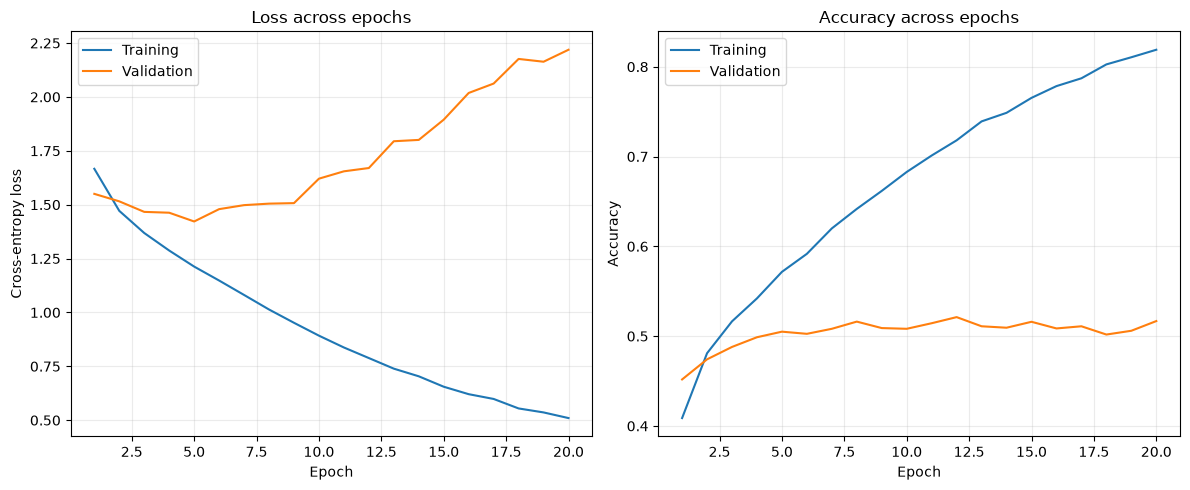

Final evaluation-mode train: loss=0.4464, accuracy=0.8423
Final validation: loss=2.2189, accuracy=0.5168


In [5]:
epochs = range(1, EPOCHS + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].plot(epochs, history["train_loss"], label="Training")
axes[0].plot(epochs, history["val_loss"], label="Validation")
axes[0].set(title="Loss across epochs", xlabel="Epoch", ylabel="Cross-entropy loss")
axes[0].legend(); axes[0].grid(alpha=0.25)
axes[1].plot(epochs, history["train_accuracy"], label="Training")
axes[1].plot(epochs, history["val_accuracy"], label="Validation")
axes[1].set(title="Accuracy across epochs", xlabel="Epoch", ylabel="Accuracy")
axes[1].legend(); axes[1].grid(alpha=0.25)
fig.tight_layout()
fig.savefig(ARTIFACT_DIR / "learning_curves.png", dpi=160)
plt.show()

final_train_loss, final_train_accuracy = evaluate(model, train_eval_loader)
final_val_loss, final_val_accuracy = evaluate(model, val_loader)
print("Final evaluation-mode train:", f"loss={final_train_loss:.4f}, accuracy={final_train_accuracy:.4f}")
print("Final validation:", f"loss={final_val_loss:.4f}, accuracy={final_val_accuracy:.4f}")


## 7. Final evaluation on the untouched official test set

Load and evaluate the official 10,000-image test partition only after training and validation are complete. These results are reported once and are not used for model selection.

Official test loss: 2.1902
Official test accuracy: 0.5165 (51.65%)


              precision    recall  f1-score   support

    airplane       0.56      0.64      0.60      1000
  automobile       0.65      0.60      0.62      1000
        bird       0.40      0.38      0.39      1000
         cat       0.34      0.35      0.35      1000
        deer       0.43      0.49      0.46      1000
         dog       0.40      0.44      0.42      1000
        frog       0.60      0.53      0.56      1000
       horse       0.65      0.53      0.58      1000
        ship       0.63      0.65      0.64      1000
       truck       0.56      0.56      0.56      1000

    accuracy                           0.52     10000
   macro avg       0.52      0.52      0.52     10000
weighted avg       0.52      0.52      0.52     10000



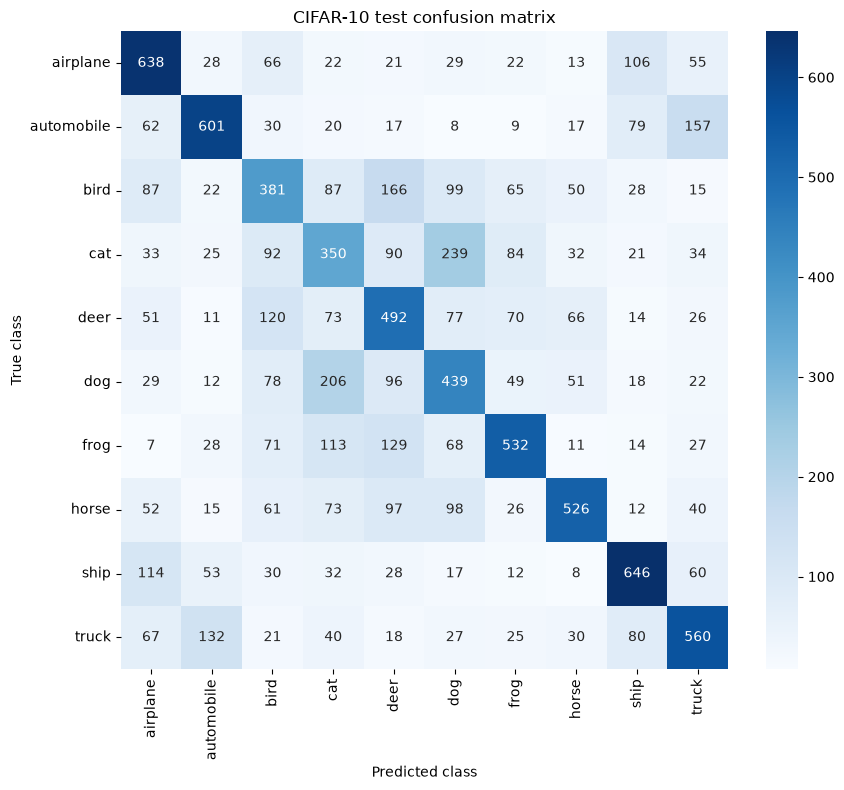

In [6]:
test_dataset = datasets.CIFAR10(
    root=str(DATA_DIR), train=False, download=DOWNLOAD_DATA, transform=transform
)
assert len(test_dataset) == 10_000
test_loader = DataLoader(test_dataset, shuffle=False, **loader_args)
test_loss, test_accuracy, y_true, y_pred = evaluate(
    model, test_loader, collect_predictions=True
)
print(f"Official test loss: {test_loss:.4f}")
print(f"Official test accuracy: {test_accuracy:.4f} ({100 * test_accuracy:.2f}%)")
report_text = classification_report(y_true, y_pred, target_names=CLASS_NAMES, zero_division=0)
report = classification_report(y_true, y_pred, target_names=CLASS_NAMES, output_dict=True, zero_division=0)
print(report_text)
cm = confusion_matrix(y_true, y_pred)
fig, ax = plt.subplots(figsize=(9, 8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax)
ax.set(xlabel="Predicted class", ylabel="True class", title="CIFAR-10 test confusion matrix")
fig.tight_layout()
fig.savefig(ARTIFACT_DIR / "confusion_matrix.png", dpi=160)
plt.show()


## 8. Save the final model and results

Save the final-epoch checkpoint and measured metrics for use in the Exercise 2 comparison.

In [7]:
final_metrics = {
    "train": {"loss": final_train_loss, "accuracy": final_train_accuracy},
    "validation": {"loss": final_val_loss, "accuracy": final_val_accuracy},
    "test": {"loss": test_loss, "accuracy": test_accuracy},
}
results = {
    "seed": SEED,
    "split_seed": 42,
    "device": str(DEVICE),
    "trainable_layers": len(trainable_layers),
    "trainable_parameters": TRAINABLE_PARAMETERS,
    "batch_size": BATCH_SIZE,
    "epochs": EPOCHS,
    "learning_rate": LEARNING_RATE,
    "split_sizes": {"train": len(train_dataset), "validation": len(val_dataset), "official_test": len(test_dataset)},
    "training_seconds": training_seconds,
    "history": history,
    "final_metrics": final_metrics,
    "classification_report": report,
}
torch.save({"model_state_dict": model.cpu().state_dict(), "seed": SEED, "class_names": CLASS_NAMES}, ARTIFACT_DIR / "mlp_classifier.pth")
model.to(DEVICE)
with (ARTIFACT_DIR / "results.json").open("w", encoding="utf-8") as f:
    json.dump(results, f, indent=2)
with (ARTIFACT_DIR / "classification_report.json").open("w", encoding="utf-8") as f:
    json.dump(report, f, indent=2)
np.savetxt(ARTIFACT_DIR / "confusion_matrix.csv", cm, delimiter=",", fmt="%d")
print("Saved model and results to:", ARTIFACT_DIR)


Saved model and results to: D:\AI ML\AI-ML-assessment-cifar10-project\artifacts\exercise_1


## 9. Results and discussion

The discussion is generated from the executed training history, final evaluation-mode metrics, and official test classification report.

In [8]:
best_epoch = int(np.argmax(history["val_accuracy"]) + 1)
min_val_loss_epoch = int(np.argmin(history["val_loss"]) + 1)
class_recalls = {name: report[name]["recall"] for name in CLASS_NAMES}
weakest_class = min(class_recalls, key=class_recalls.get)
strongest_class = max(class_recalls, key=class_recalls.get)
train_val_gap_pp = 100 * (final_train_accuracy - final_val_accuracy)
train_test_gap_pp = 100 * (final_train_accuracy - test_accuracy)
val_loss_min = min(history["val_loss"])
val_loss_final = history["val_loss"][-1]
train_loss_initial = history["train_loss"][0]
train_loss_final = history["train_loss"][-1]
analysis = f"""### Measured results and overfitting

The MLP **overfits** this training split. Validation loss reached its minimum of **{val_loss_min:.4f}** at epoch **{min_val_loss_epoch}**, then rose to **{val_loss_final:.4f}** by epoch {EPOCHS}, while training loss kept falling from **{train_loss_initial:.4f}** to **{train_loss_final:.4f}**. Final evaluation-mode accuracy was **{final_train_accuracy:.2%}** on training data, **{final_val_accuracy:.2%}** on validation data, and **{test_accuracy:.2%}** on the official test set. The train-to-validation gap was **{train_val_gap_pp:.2f} percentage points (pp)** and the train-to-test gap was **{train_test_gap_pp:.2f} pp**.

On the test set, recall was lowest for **{weakest_class}** ({class_recalls[weakest_class]:.2%}) and highest for **{strongest_class}** ({class_recalls[strongest_class]:.2%}). The class report and confusion matrix describe test errors; test results were not used for model selection.

The MLP maps flattened pixels through dense layers. Flattening does not preserve explicit neighborhood structure, and dense weights are not shared across image locations. A CNN can learn local filters and reuse them across the image, which gives it a useful inductive bias for image data. This comparison uses one seed and no data augmentation."""
display(Markdown(analysis))

### Measured results and overfitting

The MLP **overfits** this training split. Validation loss reached its minimum of **1.4221** at epoch **5**, then rose to **2.2189** by epoch 20, while training loss kept falling from **1.6666** to **0.5098**. Final evaluation-mode accuracy was **84.23%** on training data, **51.68%** on validation data, and **51.65%** on the official test set. The train-to-validation gap was **32.55 percentage points (pp)** and the train-to-test gap was **32.58 pp**.

On the test set, recall was lowest for **cat** (35.00%) and highest for **ship** (64.60%). The class report and confusion matrix describe test errors; test results were not used for model selection.

The MLP maps flattened pixels through dense layers. Flattening does not preserve explicit neighborhood structure, and dense weights are not shared across image locations. A CNN can learn local filters and reuse them across the image, which gives it a useful inductive bias for image data. This comparison uses one seed and no data augmentation.